In [ ]:
!gdown 1ZRbI4ZixHQzyglhDOSIuGjq3aXLDAAa0
!unzip -q 44dataset.zip

Downloading...
From (original): https://drive.google.com/uc?id=1ZRbI4ZixHQzyglhDOSIuGjq3aXLDAAa0
From (redirected): https://drive.google.com/uc?id=1ZRbI4ZixHQzyglhDOSIuGjq3aXLDAAa0&confirm=t&uuid=6248cbe4-8fde-4188-83cd-db0c7dd6e921
To: /content/44dataset.zip
100% 197M/197M [00:05<00:00, 34.7MB/s]


In [ ]:
import torch
from torch.utils.data import DataLoader, random_split
from torchvision.datasets import ImageFolder
from torchvision.transforms import v2
from tqdm.notebook import tqdm

def get_transform(path):
    dataset = ImageFolder(path, transform=v2.Compose([
        v2.Resize(size=(224, 224)),
        v2.PILToTensor(),
        v2.ToDtype(torch.float32, scale=True)
    ]))

    mean = torch.zeros(3)
    for image, _ in tqdm(dataset, "Computing mean"):
        mean += image.mean(dim=(1, 2))
    mean /= len(dataset)

    mean_img = mean.view(3, 1, 1).expand(-1, 224, 224)

    std = torch.zeros(3)
    for image, _ in tqdm(dataset, "Computing std"):
        d = image - mean_img
        std += (d * d).mean(dim=(1, 2))
    std = torch.sqrt((std / len(dataset)))

    print(mean, std)

    transform_augment = v2.Compose([
        v2.Resize(size=(224, 224)),
        v2.RandomRotation(degrees=7.2),
        v2.RandomHorizontalFlip(),
        v2.RandomVerticalFlip(),

        v2.PILToTensor(),
        v2.ToDtype(torch.float32, scale=True),
        v2.Normalize(mean, std)
    ])

    transform = v2.Compose([
        v2.Resize(size=(224, 224)),
        v2.PILToTensor(),
        v2.ToDtype(torch.float32, scale=True),
        v2.Normalize(mean, std)
    ])

    return transform_augment, transform

transform_augment, transform = get_transform("44_classes/Training")
dataset = ImageFolder("44_classes/Training", transform=transform_augment)

Computing mean:   0%|          | 0/3117 [00:00<?, ?it/s]

Computing std:   0%|          | 0/3117 [00:00<?, ?it/s]

tensor([0.1848, 0.1848, 0.1848]) tensor([0.2034, 0.2034, 0.2034])


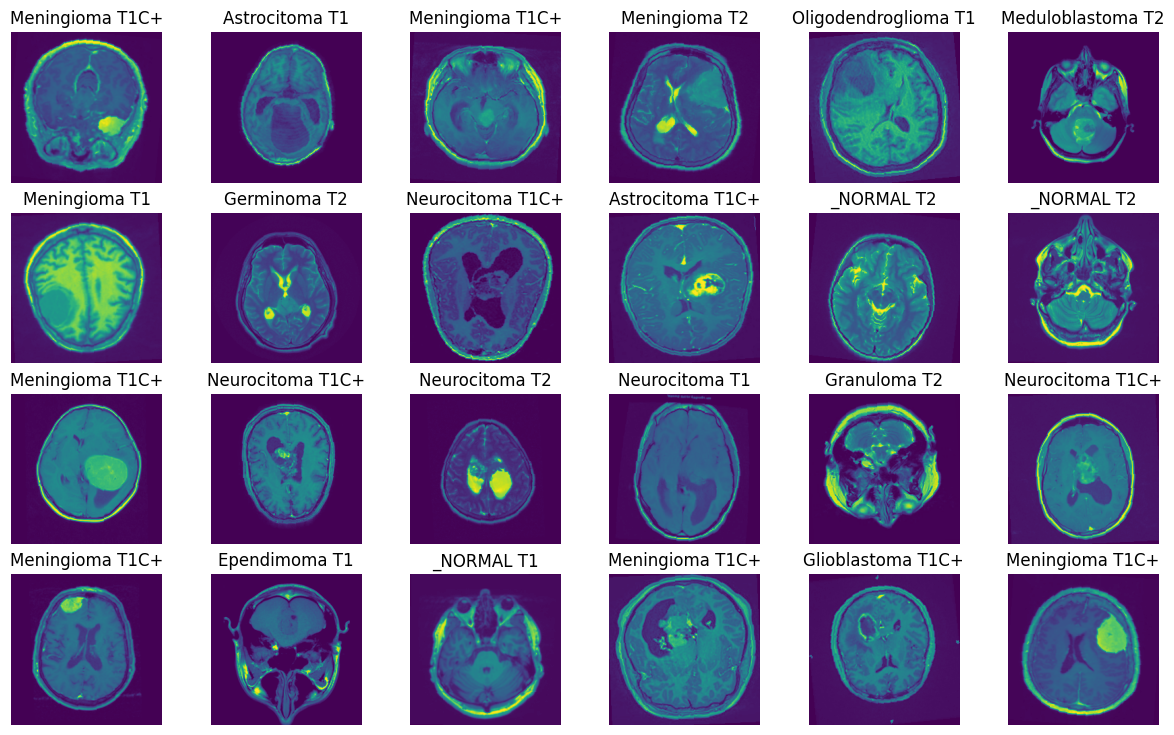

In [ ]:
import matplotlib.pyplot as plt

def visualize(dataset, seed):
    n_rows = 4
    n_cols = 6
    torch.manual_seed(seed)
    rng = torch.Generator().manual_seed(seed)
    loader = DataLoader(dataset, n_rows * n_cols, True, generator=rng)

    imgs, labels = next(iter(loader))

    imgs = imgs.view([n_rows, n_cols] + list(imgs.shape[1:]))
    labels = labels.view([n_rows, n_cols] + list(labels.shape[1:]))

    fig, ax = plt.subplots(n_rows, n_cols, figsize=(15, 9))
    for i in range(n_rows):
        for j in range(n_cols):
            ax[i][j].imshow(imgs[i][j].mean(dim=0))
            ax[i][j].set_title(dataset.classes[labels[i][j].item()])
            ax[i][j].axis("off")

    return fig

visualize(dataset, 42).show()

In [ ]:
class FL_Node:
    def __init__(self, name: str, model, dataset, loss_fn, metric_fn, lr, verbose, device):
        self.name = name
        self.rng = torch.Generator().manual_seed(hash(name))
        self.net = model().to(device)
        self.dataset = dataset
        self.data_loader = DataLoader(self.dataset, 64, True, generator=self.rng)
        self.dataset_size = len(self.dataset)
        self.loss_fn = loss_fn
        self.metric_fn = metric_fn
        self.verbose = verbose
        self.device = device
        self.lr = lr


    @torch.no_grad()
    def get_parameters(self):
        return self.net.state_dict()


    @torch.no_grad()
    def set_parameters(self, params):
        self.net.load_state_dict(params)


    def fit(self, params, epochs):
        self.set_parameters(params)

        optimizer = torch.optim.Adam(self.net.parameters(), lr=self.lr)

        self.net.train()
        for epoch in range(epochs):
            epoch_loss = torch.zeros(1, device=self.device)
            pbar = tqdm(self.data_loader, disable=not self.verbose)
            for i, (data, target) in enumerate(pbar):
                data = data.to(device)
                target = target.to(device)
                optimizer.zero_grad()

                output = self.net(data)
                loss = self.loss_fn(output, target)

                epoch_loss = epoch_loss + loss.detach()

                loss.backward()
                optimizer.step()

                pbar.set_description(f'{self.name} | Epoch: {epoch+1}/{epochs} | Train Loss: {(epoch_loss / (i + 1)).item():.4f}')

        return self.get_parameters()


    @torch.no_grad
    def evaluate(self):
        self.net.eval()
        val_loss = torch.zeros(1, device=self.device)
        val_acc  = torch.zeros(1, device=self.device)
        pbar = tqdm(self.data_loader, disable=not self.verbose)
        for i, (data, target) in enumerate(pbar):
            data = data.to(device)
            target = target.to(device)

            output = self.net(data)
            loss = self.loss_fn(output, target)
            acc = self.metric_fn(output, target)

            val_loss = val_loss + loss.detach()
            val_acc  = val_acc + acc.detach()
            pbar.set_description(f'Validation Loss: {(val_loss / (i + 1)).item():.4f} - Accuracy: {(val_acc / (i + 1)).item():.4f}')

        return (val_loss / (i + 1)).item(), (val_acc / (i + 1)).item()

In [ ]:
from torch.utils.data import random_split
from torchvision.models import resnet50, ResNet50_Weights
from torch import nn

def create_model_resnet():
    model = resnet50(weights=ResNet50_Weights.DEFAULT)
    model.fc = nn.Sequential(
        nn.Linear(model.fc.in_features, 512),
        nn.ReLU(),
        nn.Linear(512, 44),
    )
    return model

def get_weights(dataset, n_classes):
    weights = torch.zeros(n_classes)
    for _, label in dataset:
        weights[label] += 1

    return len(dataset) / (n_classes * weights)

def accuracy(output, target):
    return (output.argmax(1) == target).float().mean()

def create_clients(dataset, n_classes, n_clients, lr, rng, device):
    size_per_client = (len(dataset) + (n_clients) // 2) // n_clients
    last_size = len(dataset) - size_per_client * (n_clients - 1)

    subset_sizes = [size_per_client] * (n_clients - 1) + [last_size]
    datasets = random_split(dataset, subset_sizes, rng)
    return [
        FL_Node(f"Client {i}", create_model_resnet, subset,
                nn.CrossEntropyLoss(get_weights(subset, n_classes).to(device)), accuracy,
                lr, False, device)
        for i, subset in enumerate(tqdm(datasets, "Creating clients"))
    ]

def create_server(dataset, n_classes, device):
    return FL_Node("Server", create_model_resnet, dataset,
                   nn.CrossEntropyLoss(get_weights(dataset, n_classes).to(device)), accuracy,
                   0.0, False, device)

In [ ]:
class Aggregator:
    def __init__(self, clients, epoch_per_client):
        self.clients = clients
        self.epoch_per_client = epoch_per_client
        self.dataset_size = sum(client.dataset_size for client in clients)

    def fit(self, params, epochs):
        for epoch in range(epochs):
            next_params = {}

            for client in self.clients:
                fraction = client.dataset_size / self.dataset_size
                client_params = client.fit(params, self.epoch_per_client)
                with torch.no_grad():
                    for name, data in client_params.items():
                        if name not in next_params:
                            next_params[name] = fraction * data
                        else:
                            next_params[name] += fraction * data

            params = next_params
        return params

In [ ]:
def create_sub_globals(clients, n_subs, epoch_per_client):
    size_per_sub = (len(clients) + n_subs // 2) // n_subs
    last_size = len(clients) - size_per_sub * (n_subs - 1)
    return [Aggregator(clients[:last_size], epoch_per_client)] + [
        Aggregator(clients[i:i + size_per_sub], epoch_per_client)
        for i in range(last_size, len(clients), size_per_sub)
    ]

In [ ]:
def train_hierarchical(dataset, rounds, sub_rounds, epoch_per_client, seed, device):
    rng = torch.Generator().manual_seed(seed)
    torch.manual_seed(seed)
    n_classes = len(dataset.classes)
    train_dataset, valid_dataset = random_split(dataset, [0.8, 0.2], generator=rng)

    clients = create_clients(train_dataset, n_classes, 20, 3e-4, rng, device)
    server = create_server(valid_dataset, n_classes, device)

    sub_globals = create_sub_globals(clients, 5, epoch_per_client)
    aggregator = Aggregator(sub_globals, sub_rounds)

    best_model = server.get_parameters()
    _, best_metric = server.evaluate()

    hist = []
    for i in range(rounds):
        print(f"Starting round {i + 1} ...", end=' ', flush=True)
        server.set_parameters(aggregator.fit(server.get_parameters(), 1))
        loss, metric = server.evaluate()
        hist.append((loss, metric))
        if metric > best_metric:
            best_metric = metric
            best_model = server.get_parameters()
        print(f"Loss: {loss} - Metric: {metric}")

    server.set_parameters(best_model)

    return (server.net, hist)

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
model, hist = train_hierarchical(dataset, 20, 10, 1, 42, device)

Creating clients:   0%|          | 0/20 [00:00<?, ?it/s]

Starting round 1 ... Loss: 3.774228811264038 - Metric: 0.0495678186416626
Starting round 2 ... Loss: 3.766009569168091 - Metric: 0.078125
Starting round 3 ... Loss: 3.7475433349609375 - Metric: 0.11801861971616745
Starting round 4 ... Loss: 3.719259262084961 - Metric: 0.1498337835073471
Starting round 5 ... Loss: 3.6811611652374268 - Metric: 0.20252659916877747
Starting round 6 ... 

In [ ]:
import seaborn as sn
import pandas as pd

def visualize_test(model, test_dataset, dataset):
    confusion_matrix = torch.zeros((len(dataset.classes), len(dataset.classes)))
    correct = 0
    pbar = tqdm(test_dataset)

    for i, (image, label) in enumerate(pbar):
        pred = model(image.unsqueeze(0).to(device)).argmax(1).item()
        label = dataset.class_to_idx[test_dataset.classes[label]]
        confusion_matrix[label][pred] += 1
        if pred == label:
            correct += 1
        pbar.set_description(f"Accuracy: {correct * 100 / (i + 1):.4f}%")

    fig, ax = plt.subplots(figsize=(12, 12))
    df = pd.DataFrame(confusion_matrix, index=dataset.classes, columns=dataset.classes)
    sn.heatmap(df, square=True)
    print(correct / len(test_dataset))

test_dataset = ImageFolder("44_classes/Testing", transform=transform)
visualize_test(model, test_dataset, dataset)